# FCS Analysis of Real Experimental Data

**Purpose.** Apply the FCS analysis pipeline validated on simulations 
(`3a_simulation_analysis.ipynb`) to real PicoQuant photon-counting histograms 
of EtBr (free) and EtBr + EtBr-DNA solutions.

**Key differences from simulations.**
- No particle IDs: signal and background photons are **inseparable**.
- Tick resolution: 100 ns (PicoQuant time-to-photon), vs 1 $\mu s$ in simulation.
- Background fluorescence is always present and Poissonian.

**Workflow.**
1. **Free EtBr** (Sol01_m1): single-species fit to extract $\tau_{free}$ and 
   $N_{eff}^{real}$ (apparent, background-diluted).
2. **EtBr + EtBr-DNA** (Sol05_m1): test the unburst workflow on real data. 
   Compare with the direct 2-species fit on raw data.

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import pycorrelate as pyc
from scipy.optimize import curve_fit
# load integrated toolkit functions in the project repo
import toolkit as tk
import tomli
# define paths to handle data smoothly
path_realts_m1 = './Real_data/m1/'

# I. **Free EtBr** – Real data (Sol01_m1)
Load the free-EtBr measurement, compute the ACF and fit a single-species 3D-diffusion model to extract $\tau_{diff}$.

In [2]:
# load real data timestamps (PicoQuant .asc)
ts_free_real = tk.load_asc_timestamps(path_realts_m1, 'Sol01_m1.asc')
print(f'Total photons: {len(ts_free_real)} | Duration: {ts_free_real.max():.1f} s')

Total photons: 101176 | Duration: 180.0 s


#### Create histogram to get first statistics

The histogram is computed (bin width = 10 ms) and the median and MAD of the 
bin counts are extracted as robust descriptors of the signal. Here the distribution is narrow 
(median = 5 cps, MAD = 3 cps), consistent with a low count rate (~562 cps) and no 
visible burst population.

In [3]:
bins_free = np.arange(0, ts_free_real.max(), 1e-2)
stats_free = tk.trace_stats(ts_free_real, bins=bins_free)
median_free = stats_free['median']
MAD_free = stats_free['MAD']
print(f'Median: {median_free:.2f} cps | MAD: {MAD_free:.2f} cps')

Median: 5.00 cps | MAD: 2.97 cps


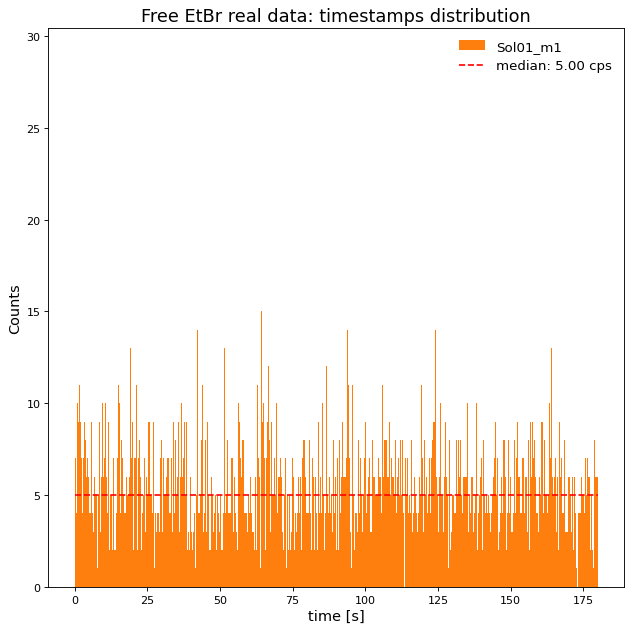

In [4]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("Free EtBr real data: timestamps distribution", fontsize=16)
ax.hist(ts_free_real, bins=bins_free, color="tab:orange", lw=1, label='Sol01_m1')
ax.hlines(median_free, 0, ts_free_real.max(), 'red', linestyle='--',
           label=f'median: {median_free:.2f} cps')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_free_etbr_real.png')

#### Estimate average count rate

In [5]:
F_free_real = ts_free_real.size / ts_free_real.max()
print(f"Count rate: {F_free_real:.2f} cps")

Count rate: 562.04 cps


#### Choose the fit range: $\tau_{lo}$ sweep

The ACF is fitted only on a restricted lag-time window $[\tau_{lo}, \tau_{hi}]$, and both bounds must be chosen with care:

- **Short-lag cutoff ($\tau_{lo}$).** Below a few tens of $\mu s$ the ACF is unreliable for two reasons. First, *statistics*: with ~560 cps and a 180 s acquisition, only a few dozen photon pairs fall in each short lag bin, so the relative error there is large. Second, *instrumental effects*: the finite tick resolution (100 ns), detector afterpulsing and dead time distort the ACF at very short delays. Including these points biases $\tau_{diff}$.
- **Long-lag cutoff ($\tau_{hi}$).** At long lags the photon-pair count $Y(\tau)$ becomes too small and the ACF collapses into noise around the baseline; beyond a few tens of seconds it carries no information about the diffusing species.

Operationally, $\tau_{hi} = 100$ s is fixed and only **$\tau_{lo}$ is swept from 2 to 48 $\mu s$** (step 2 $\mu s$): at each step the fit window is shifted and the fit redone, so that one can see how much $\tau_{diff}$ changes as the lower bound moves. The correct $\tau_{lo}$ is then identified as the shortest lag for which $\tau_{diff}$ reaches a stable plateau — i.e. the value below which the short-lag artefacts start pulling the result away.

In [6]:
# PSF from simulation parameters (same microscope, used as initial guess)
params = tomli.load(open("parameters.toml", 'rb'))
W0_sm = params['PSF']['w0_eff']
Z0_sm = params['PSF']['z0_eff']

# Define tick unit for ACF time-lag and maximum time
unit_free = 1e-7  # PicoQuant tick ~100 ns
T_free = ts_free_real.max()

# Compute ACF
tau_free, G_free, Y_free = tk.compute_G(ts_free_real, ts_free_real, unit_free, T_free, bins_per_dec=200)

# Initial guesses and bounds (single species: [tau_diff, A0])
pars_free = [50e-6, 1.0]
bounds_free = ([1e-8, 1e-3], [1e-2, 1e3])
sigma_free = 1.0 / np.sqrt(np.maximum(Y_free, 1))

# Sweep tau_lo from 2 to 48 us (step 2 us), tau_hi = 100 s
tau_hi = 1e2
sweep_results = []
for tau_lo_us in range(2, 50, 2):
    tau_lo = tau_lo_us * 1e-6
    popt_s, pcov_s, _, _ = tk.fit_G(
        tau_free, G_free, pars_free, bounds_free,
        model="single",
        tau_range=(tau_lo, tau_hi), sigma=sigma_free, W0=W0_sm, Z0=Z0_sm
    )
    perr_s = np.sqrt(np.diag(pcov_s))
    sweep_results.append({
        'tau_lo [us]': tau_lo_us,
        'tau_diff [us]': popt_s[0]*1e6,
        'tau_diff_err [us]': perr_s[0]*1e6,
        'A0': popt_s[1],
        'N_eff': 1.0/popt_s[1]
    })

sweep_df = pd.DataFrame(sweep_results).set_index('tau_lo [us]')
display(sweep_df)

,tau_diff [us],tau_diff_err [us],A0,N_eff
tau_lo [us],,,,
2,22.734153,3.766779,0.573718,1.743016
4,22.733294,4.230446,0.573233,1.744491
6,31.971015,6.703155,0.446633,2.238976
8,35.824412,8.117650,0.410334,2.437040
10,40.290218,9.734317,0.374964,2.666924
12,34.786951,8.855573,0.420977,2.375426
14,30.442997,8.227710,0.468592,2.134054
16,21.966380,6.505266,0.616516,1.622017
18,25.038300,7.764136,0.550675,1.815954


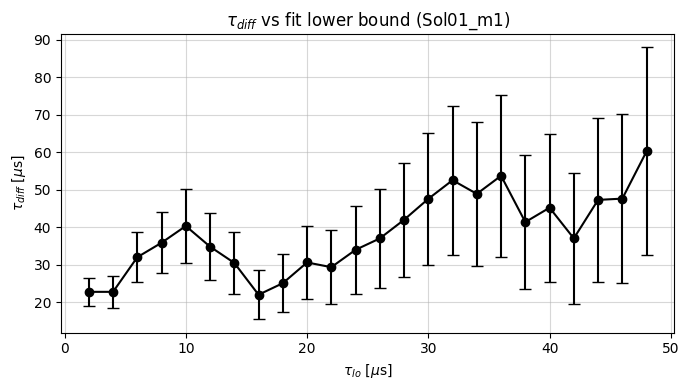

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    sweep_df.index, sweep_df['tau_diff [us]'],
    yerr=sweep_df['tau_diff_err [us]'],
    marker='o', capsize=4, color='black'
)
ax.set_xlabel('$\\tau_{lo}$ [$\\mu$s]')
ax.set_ylabel('$\\tau_{diff}$ [$\\mu$s]')
ax.set_title('$\\tau_{diff}$ vs fit lower bound (Sol01_m1)')
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.savefig('./images/tau_range_sweep_free_real.png')

**Observation.** The sweep shows a clear trend: for $\tau_{lo} < 28\,\mu s$ the fitted $\tau_{diff}$ is systematically too low and strongly oscillating (from $22.7\,\mu s$ at $\tau_{lo} = 2\,\mu s$ up to a maximum of $41.9\,\mu s$ at $\tau_{lo} = 28\,\mu s$, with no monotonic behaviour: e.g. $35.8$ at $8\,\mu s$ vs $21.9$ at $16\,\mu s$). This is the signature of the short-lag distortions discussed above — finite tick resolution (100 ns), afterpulsing and dead time — which pull the fit depending on exactly which noisy bins are included.

For $\tau_{lo} \geq 30\,\mu s$ the values stabilise into a plateau between $41$ and $54\,\mu s$ (e.g. $47.5$, $52.5$, $48.9$, $53.7$ at $\tau_{lo} = 30$–$36\,\mu s$), all mutually consistent within their (increasing) error bars. The point-to-point scatter grows with $\tau_{lo}$ because fewer ACF points remain in the fit window; at $\tau_{lo} = 48\,\mu s$ the last point ($60.2 \pm 27.8\,\mu s$) is already dominated by statistics.

$\tau_{lo} = 30\,\mu s$ is chosen as the lower fit bound: it is the shortest lag at which $\tau_{diff}$ enters the plateau ($47.5 \pm 17.6\,\mu s$, consistent with the expected diffusion time of free EtBr, $D \approx 425\,\mu m^2/s \Rightarrow \tau_D = w_0^2/(4D) \approx 53\,\mu s$), and it keeps as many data points in the window as possible.

In [8]:
# Final fit with tau_range = (30 us, 100 s)
tau_range_free = (30e-6, 1e2)

popt_free, pcov_free, W0_fit_free, Z0_fit_free = tk.fit_G(
    tau_free, G_free, pars_free, bounds_free,
    model="single",
    tau_range=tau_range_free, sigma=sigma_free, W0=W0_sm, Z0=Z0_sm
)

#### Extract $N_{eff}$ and $\tau_{diff}$ from the fit

In [9]:
# Fit parameters
tau_free_fit, A0_free = popt_free
perr_free = np.sqrt(np.diag(pcov_free))
tau_free_err, A0_free_err = perr_free

# N_eff from A0
N_free_real = 1.0 / A0_free
N_free_real_err = N_free_real * A0_free_err / A0_free

# Diffusion coefficient (using the PSF guess)
D_free_fit = W0_fit_free**2 / (4 * tau_free_fit)
D_free_err = D_free_fit * tau_free_err / tau_free_fit

# Tabulate results
summary_free = pd.DataFrame({
    'Sample': ['Sol01_m1 (FIT)'],
    'tau_diff [us]': [tau_free_fit*1e6],
    'tau_diff_err [us]': [tau_free_err*1e6],
    'D [um^2/s]': [D_free_fit*1e12],
    'D_err [um^2/s]': [D_free_err*1e12],
    'A0': [A0_free],
    'A0_err': [A0_free_err],
    'N_eff': [N_free_real],
    'N_eff_err': [N_free_real_err]
}).set_index('Sample')

styled_free = summary_free.style.format({
    'tau_diff [us]': '{:.2f}', 'tau_diff_err [us]': '{:.2f}',
    'D [um^2/s]': '{:.2f}', 'D_err [um^2/s]': '{:.2f}',
    'A0': '{:.3g}', 'A0_err': '{:.3g}',
    'N_eff': '{:.3g}', 'N_eff_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_free)

,tau_diff [us],tau_diff_err [us],D [um^2/s],D_err [um^2/s],A0,A0_err,N_eff,N_eff_err
Sample,,,,,,,,
Sol01_m1 (FIT),47.53,17.64,473.37,175.68,0.319,0.0895,3.14,0.882


#### Plot ACF and fit

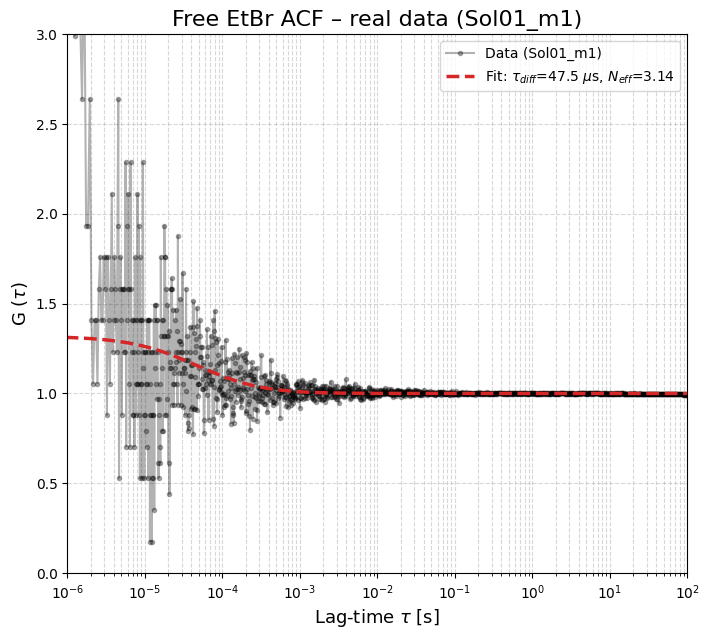

In [28]:
G_fit_free = tk.diffusion_3d_single(tau_free, *popt_free)

fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("Free EtBr ACF – real data (Sol01_m1)", fontsize=16)
ax.plot(
    tau_free, G_free, '.-', color='black', alpha=0.3,
    label='Data (Sol01_m1)',
)
ax.plot(
    tau_free, G_fit_free, '--', color='tab:red', lw=2.5,
    label=f'Fit: $\\tau_{{diff}}$={tau_free_fit*1e6:.1f} $\\mu$s, $N_{{eff}}$={N_free_real:.2f}'
)
# ax.axvline(30e-6, color='black', linestyle='--', lw=1,
#            label='$\\tau_{lo}$ = 30 $\\mu$s')
ax.set_xlabel("Lag-time $\\tau$ [s]", fontsize= 13)
ax.set_ylabel("G ($\\tau$)", fontsize=13)
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0, 3)
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_free_etbr_real.png')

#### Note on background and its effect on $N_{eff}$

In real data signal photons cannot be separated from background photons (unlike in the simulation, 
where particle IDs allow an exact split). The background is Poissonian and uncorrelated, so it:

- **Does NOT affect $\tau_{diff}$**: the decay shape of the ACF is unchanged. The fitted 
  $\tau_{free} = 47.5$ $\mu s$ is therefore valid regardless of the background level.

- **Dilutes $A_0$** by a factor $\alpha = (F_{sig}/F_{tot})^2 < 1$, making the apparent 
  $N_{eff}^{app} = 1/A_0^{fit}$ **larger** than the true number of molecules:
  $$N_{true} = N_{eff}^{app} \cdot \alpha = N_{eff}^{app} \left(\frac{F_{sig}}{F_{tot}}\right)^2$$

**Why this is not a problem for the workflow:**  
The same background is present in all measurements (same setup, same laser, same optics). 
When the two-species model is fitted on the EtBr+DNA data, the recovered $N_{free}$ is subject to 
the **same** systematic dilution. Therefore the comparison is:

$$N_{free}^{app}(\text{EtBr+DNA fit}) \quad \text{vs} \quad N_{free}^{app}(\text{EtBr free}) = 3.14$$

Both values carry the same offset, so the comparison is consistent without any background 
correction. The reference value to use in subsequent analyses is **$N_{free}^{app} = 3.14$**.

# II. **EtBr + EtBr-DNA** – Real data (Sol03_m1)

The unburst workflow is now tested on real data. The goal is to verify whether the 
$k \cdot MAD$ threshold method, validated on noise-free simulations, remains applicable 
when Poissonian background is present and inseparable from the signal.

In [11]:
# load real data timestamps (PicoQuant .asc)
ts_dna_real = tk.load_asc_timestamps(path_realts_m1, 'Sol03_m1.asc')
print(f'Total photons: {len(ts_dna_real)} | Duration: {ts_dna_real.max():.1f} s')

Total photons: 857935 | Duration: 161.4 s


#### Histogram and statistics

In [12]:
bins_dna = np.arange(0, ts_dna_real.max(), 1e-2)
stats_dna = tk.trace_stats(ts_dna_real, bins=bins_dna)
median_dna = stats_dna['median']
MAD_dna = stats_dna['MAD']
F_dna = ts_dna_real.size / ts_dna_real.max()
print(f'Median: {median_dna:.2f} cps | MAD: {MAD_dna:.2f} cps')
print(f'Count rate: {F_dna:.1f} cps')

Median: 44.00 cps | MAD: 11.86 cps
Count rate: 5314.7 cps


**Observation.** The histogram (median = 44 cps, MAD = 11.9 cps in 10 ms bins) shows a **broad, unimodal** distribution with no clear gap between a low-count "signal" population and a high-count "burst" population. This contrasts sharply with the simulations, where free EtBr (~600 cps) and DNA bursts (~10 000 cps) formed two well-separated peaks.

The total count rate is ~5 300 cps (vs ~800 cps in the simulation), meaning the background contributes a large fraction of the detected photons. The MAD is consequently inflated by Poisson noise of the dense signal, not just by bursts.

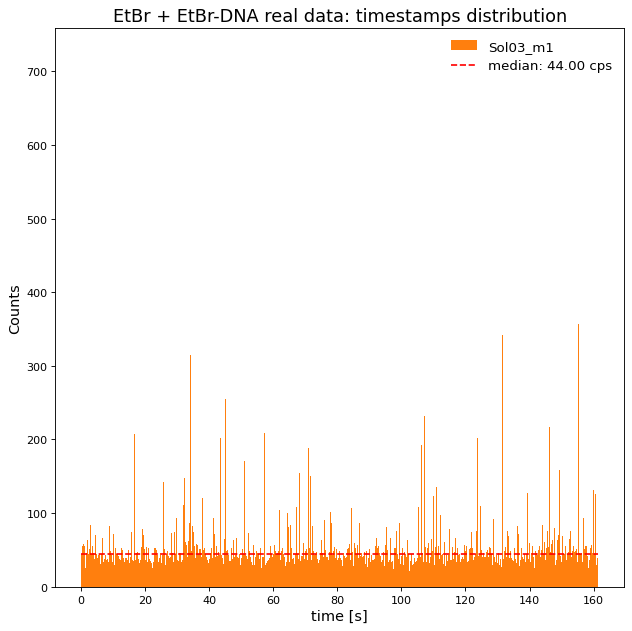

In [13]:
fig = plt.figure(figsize=(8,8), dpi=80)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA real data: timestamps distribution", fontsize=16)
ax.hist(ts_dna_real, bins=bins_dna, color="tab:orange", lw=1, label='Sol03_m1')
ax.hlines(median_dna, 0, ts_dna_real.max(), 'red', linestyle='--',
           label=f'median: {median_dna:.2f} cps')
ax.set_xlabel('time [s]', fontsize=13)
ax.set_ylabel('Counts', fontsize=13)
ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.draw()
plt.savefig('./images/hist_etbr_dna_real_Sol03.png')

#### Key observation: signal-to-burst ratio

To set the unburst threshold, the same robust estimators introduced in the simulation
notebook are reused:

- **Median**: $\text{median} = x_{(N/2)}$, insensitive to a few extreme bins.
- **MAD**: $\text{MAD} = \text{median}(|x_i - \text{median}|)$, the robust analogue of 
  $\sigma$ (for a Gaussian, $\sigma = 1.4826 \times \text{MAD}$), not inflated by heavy tails.

The threshold is $thr = \text{median} + k \cdot \text{MAD}$.

**Expectation.** In the simulations free EtBr emitted at ~600 cps while DNA-EtBr bursts 
reached ~10 000 cps (ratio ≈ 17×, with a **clear gap** between the two populations in 
the histogram). The $median + k \cdot MAD$ threshold could exploit this gap to isolate 
bursts, so one would *expect* the same preprocessing to work here as well.

**Reality.** In the real data, the total count rate is ~5 300 cps and the histogram shows a 
**continuous, broad distribution** with no clear separation between "signal" and 
"burst" populations. The MAD is inflated by the Poisson noise of the dense signal, 
making the threshold ineffective at discriminating bursts from legitimate photons.

#### Threshold sweep: $k \cdot MAD$ unburst vs $N_{free}$

The sweep is still performed ($k = 0$ to $0.5$, step 0.1) to demonstrate the behaviour of the method on real data. Note that even $k = 0$ — the least aggressive step, with the threshold set at the median — already removes a large fraction of all photons (every bin above the median), so no point in the sweep is a "no unburst" control.

In [14]:
# Sweep parameters
ks = np.arange(0, 0.6, 0.1)
unit_dna = 1e-7
T_dna = ts_dna_real.max()
tau_range_dna = (50e-6, 1e2)

# tau_free fixed from the free-EtBr fit done earlier in this notebook
tau_1_fixed = tau_free_fit

# Store results
sweep_results_dna = []
for k in ks:
    thr = median_dna + k * MAD_dna
    ts_u = tk.unburst(ts_dna_real, bins=bins_dna, threshold=thr)
    if len(ts_u) < 1000:
        sweep_results_dna.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    T_u = ts_u.max()
    tau_u, G_u, Y_u = tk.compute_G(ts_u, ts_u, unit_dna, T_u, bins_per_dec=200)
    sigma_u = 1.0 / np.sqrt(np.maximum(Y_u, 1))

    # 2-species fit: [tau_1 (fixed), A0_1, tau_2, A0_2]
    pars_sweep = [tau_1_fixed, 0.3, 50e-3, 0.1]
    bounds_sweep = (
        [tau_1_fixed * 0.9, 1e-4, 1e-6, 1e-4],
        [tau_1_fixed * 1.1, 1e1,  1e1,  1e1]
    )
    try:
        popt_u, pcov_u, _, _ = tk.fit_G(
            tau_u, G_u, pars_sweep, bounds_sweep,
            model="double",
            tau_range=tau_range_dna, sigma=sigma_u, W0=W0_sm, Z0=Z0_sm
        )
        perr_u = np.sqrt(np.diag(pcov_u))
        t1, a1, t2, a2 = popt_u
        t1e, a1e, t2e, a2e = perr_u
        N1 = 1.0 / a1
        N2 = 1.0 / a2
        N1_err = N1 * a1e / a1
        N2_err = N2 * a2e / a2
    except Exception:
        sweep_results_dna.append({
            'k': k, 'tau_free': np.nan, 'tau_free_err': np.nan,
            'A0_free': np.nan, 'N_free': np.nan, 'N_free_err': np.nan,
            'tau_bound': np.nan, 'tau_bound_err': np.nan,
            'A0_bound': np.nan, 'N_bound': np.nan, 'N_bound_err': np.nan
        })
        continue

    sweep_results_dna.append({
        'k': k,
        'tau_free': t1, 'tau_free_err': t1e,
        'A0_free': a1, 'N_free': N1, 'N_free_err': N1_err,
        'tau_bound': t2, 'tau_bound_err': t2e,
        'A0_bound': a2, 'N_bound': N2, 'N_bound_err': N2_err
    })

# Convert to DataFrame
sweep_df_dna = pd.DataFrame(sweep_results_dna).set_index('k')
display(sweep_df_dna)

,tau_free,tau_free_err,A0_free,N_free,N_free_err,tau_bound,tau_bound_err,A0_bound,N_bound,N_bound_err
k,,,,,,,,,,
0.0,0.000052,0.000031,0.089886,11.125180,4.885511,0.013646,0.000013,1.789781,0.558728,0.000325
0.1,0.000052,0.000022,0.120856,8.274333,2.527111,0.014158,0.000014,1.528782,0.654116,0.000403
0.2,0.000052,0.000019,0.127134,7.865700,2.156373,0.014739,0.000015,1.324390,0.755065,0.000489
0.3,0.000052,0.000024,0.097069,10.301962,3.515657,0.015005,0.000017,1.162991,0.859852,0.000591
0.4,0.000052,0.000029,0.076933,12.998382,5.319344,0.015472,0.000018,1.021795,0.978670,0.000709
0.5,0.000052,0.000229,0.009259,108.005440,353.838773,0.014856,0.000019,0.919566,1.087469,0.000861


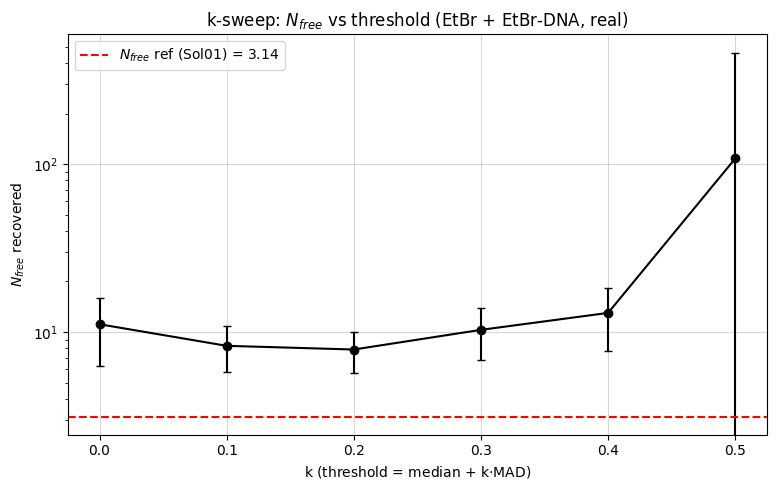

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    sweep_df_dna.index,
    sweep_df_dna['N_free'],
    yerr=sweep_df_dna['N_free_err'],
    marker='o', capsize=3, linestyle='-', color='black'
)
ax.axhline(N_free_real, color='red', linestyle='--',
           label=f'$N_{{free}}$ ref (Sol01) = {N_free_real:.2f}')
ax.set_xlabel('k (threshold = median + k$\\cdot$MAD)')
ax.set_ylabel('$N_{free}$ recovered')
ax.set_title('k-sweep: $N_{free}$ vs threshold (EtBr + EtBr-DNA, real)')
ax.legend(frameon=True)
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.draw()
plt.yscale('log')
plt.savefig('./images/sweep_k_Nfree_etbr_dna_real_Sol03.png')

**Observation.** The k-sweep confirms the failure of the unburst method on real data: no value of $k$ in the range $0$–$0.5$ yields a stable, correct $N_{free}$. Even at $k = 0$ (threshold = median), where the largest fraction of photons is removed, the fit already deviates from the free-EtBr reference ($N_{eff} = 3.14$); as $k$ increases and fewer photons are removed, the result does not converge to the reference either — the residual biased removal (always concentrated in the highest-count bins) is sufficient to distort the ACF amplitude and destabilise the fit.

**Root cause.** The method requires a bimodal histogram with a clear gap between signal and bursts. In real data, the high background count rate produces a broad, unimodal distribution where no threshold can discriminate bursts from legitimate signal.

#### Interpretation: why unburst fails on real data

The sweep shows that **no value of $k$ yields a stable, correct $N_{free}$**: every threshold removes photons in a way biased towards the highest-count bins, which in real data are not pure bursts but the dense tail of the signal + background distribution. This distorts the ACF amplitude (which determines $N_{free}$) regardless of how aggressive the threshold is.

**Root cause:** In the simulations, bursts are rare events with count rates an order of magnitude above the signal (10 000 vs 600 cps), creating a clear bimodal histogram. The $median + k \cdot MAD$ threshold exploits this gap. In real data, the high total count rate (~5 300 cps) and the Poissonian background produce a **broad, unimodal** distribution where no threshold can separate bursts from signal.

**Conclusion:** The unburst method is valid **only when the signal is clean** (low background, clear burst/signal separation). Under high-background conditions, the direct 2-species fit on raw data is the appropriate approach.

#### Unburst at $k = 0.2$ vs raw data: side-by-side comparison

To make the failure visible, the $k = 0.2$ case is treated exactly like the raw-data analysis: ACF computed on the unbursted trace, 2-species fit with $\tau_{free}$ fixed, results tabulated and plotted against the raw-data fit. Note that $k = 0.2$ is **not** a "no unburst" control — the threshold $median + 0.2 \cdot MAD$ still removes every bin above it, so any difference from the raw result measures the damage done by the threshold itself.

The raw-data ACF and its 2-species fit (with $\tau_{free}$ fixed) are computed first:

In [16]:
# Compute ACF on raw data
T_dna = ts_dna_real.max()
tau_dna, G_dna, Y_dna = tk.compute_G(ts_dna_real, ts_dna_real, unit_dna, T_dna, bins_per_dec=200)

# 2-species fit with tau_free fixed
sigma_dna = 1.0 / np.sqrt(np.maximum(Y_dna, 1))
pars_dna = [tau_1_fixed, 0.3, 50e-3, 0.1]
bounds_dna = (
    [tau_1_fixed * 0.9, 1e-4, 1e-6, 1e-4],
    [tau_1_fixed * 1.1, 1e1,  1e1,  1e1]
)
popt_dna, pcov_dna, W0_fit_dna, Z0_fit_dna = tk.fit_G(
    tau_dna, G_dna, pars_dna, bounds_dna,
    model="double",
    tau_range=tau_range_dna, sigma=sigma_dna, W0=W0_sm, Z0=Z0_sm
)

# Extract results
tau_1_fit, A0_1_fit, tau_2_fit, A0_2_fit = popt_dna
perr_dna = np.sqrt(np.diag(pcov_dna))
tau_1_err, A0_1_err, tau_2_err, A0_2_err = perr_dna

N_1 = 1.0 / A0_1_fit
N_2 = 1.0 / A0_2_fit
N_1_err = N_1 * A0_1_err / A0_1_fit
N_2_err = N_2 * A0_2_err / A0_2_fit

# Model curve for the raw-data fit (used in the comparison plot)
G_fit_dna = tk.diffusion_3d_double(tau_dna, *popt_dna)

In [17]:
# Unburst at k=0.2 (threshold = median + 0.2*MAD): same pipeline as the raw-data fit
thr_k02 = median_dna + 0.2 * MAD_dna
ts_u_k02 = tk.unburst(ts_dna_real, bins=bins_dna, threshold=thr_k02)
print(f'photons: raw = {len(ts_dna_real)} | unburst (k=0.2) = {len(ts_u_k02)} '
      f'| removed = {100*(1 - len(ts_u_k02)/len(ts_dna_real)):.1f}%')

# ACF on the unbursted trace
T_u_k02 = ts_u_k02.max()
tau_u_k02, G_u_k02, Y_u_k02 = tk.compute_G(ts_u_k02, ts_u_k02, unit_dna, T_u_k02, bins_per_dec=200)

# 2-species fit with tau_free fixed (same setup as the raw-data fit)
sigma_u_k02 = 1.0 / np.sqrt(np.maximum(Y_u_k02, 1))
pars_u_k02 = [tau_1_fixed, 0.3, 50e-3, 0.1]
bounds_u_k02 = (
    [tau_1_fixed * 0.9, 1e-4, 1e-6, 1e-4],
    [tau_1_fixed * 1.1, 1e1,  1e1,  1e1]
)
popt_u_k02, pcov_u_k02, W0_fit_u_k02, Z0_fit_u_k02 = tk.fit_G(
    tau_u_k02, G_u_k02, pars_u_k02, bounds_u_k02,
    model="double",
    tau_range=tau_range_dna, sigma=sigma_u_k02, W0=W0_sm, Z0=Z0_sm
)

# Extract results
tau_1_u_k02, A0_1_u_k02, tau_2_u_k02, A0_2_u_k02 = popt_u_k02
perr_u_k02 = np.sqrt(np.diag(pcov_u_k02))
tau_1_err_u_k02, A0_1_err_u_k02, tau_2_err_u_k02, A0_2_err_u_k02 = perr_u_k02

N_1_u_k02 = 1.0 / A0_1_u_k02
N_2_u_k02 = 1.0 / A0_2_u_k02
N_1_err_u_k02 = N_1_u_k02 * A0_1_err_u_k02 / A0_1_u_k02
N_2_err_u_k02 = N_2_u_k02 * A0_2_err_u_k02 / A0_2_u_k02

photons: raw = 857935 | unburst (k=0.2) = 259586 | removed = 69.7%


#### Summary table: raw vs unburst ($k=0.2$)

In [18]:
# Tabulate results: raw data vs unburst (k=0.2)
summary_cmp = pd.DataFrame({
    'Sample': ['Sol03_m1 (raw, 2-species)', 'Sol03_m1 (unburst k=0.2)'],
    'tau_free [us]': [tau_1_fit*1e6, tau_1_u_k02*1e6],
    'tau_free_err [us]': [tau_1_err*1e6, tau_1_err_u_k02*1e6],
    'A0_free': [A0_1_fit, A0_1_u_k02],
    'N_free': [N_1, N_1_u_k02],
    'N_free_err': [N_1_err, N_1_err_u_k02],
    'tau_bound [ms]': [tau_2_fit*1e3, tau_2_u_k02*1e3],
    'A0_bound': [A0_2_fit, A0_2_u_k02],
    'N_bound': [N_2, N_2_u_k02],
    'N_bound_err': [N_2_err, N_2_err_u_k02],
}).set_index('Sample')

styled_cmp = summary_cmp.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'tau_bound [ms]': '{:.2f}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_cmp)

# Reference value from free EtBr
ref_dna = pd.DataFrame({
    'Sample': ['Sol01_m1 (REF)'],
    'tau_free [us]': [tau_free_fit*1e6],
    'A0_free': [A0_free],
    'N_free': [N_free_real],
    'N_free_err': [N_free_real_err],
}).set_index('Sample')
styled_ref = ref_dna.style.format({
    'tau_free [us]': '{:.2f}', 'A0_free': '{:.3g}',
    'N_free': '{:.3g}', 'N_free_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_ref)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,tau_bound [ms],A0_bound,N_bound,N_bound_err
Sample,,,,,,,,,
"Sol03_m1 (raw, 2-species)",52.28,2.85,0.322,3.1,0.126,13.06,0.488,2.05,0.00141
Sol03_m1 (unburst k=0.2),52.28,19.23,0.127,7.87,2.16,14.74,1.32,0.755,0.000489


,tau_free [us],A0_free,N_free,N_free_err
Sample,,,,
Sol01_m1 (REF),47.53,0.319,3.14,0.882


#### Plot ACF and fits: raw vs unburst ($k=0.2$)

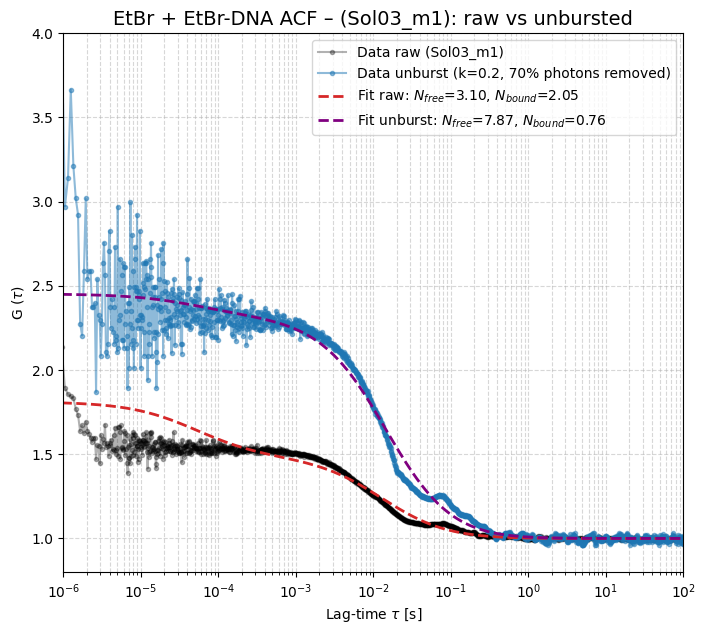

In [19]:
G_fit_u_k02 = tk.diffusion_3d_double(tau_u_k02, *popt_u_k02)

fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF – (Sol03_m1): raw vs unbursted", fontsize=14)
ax.plot(
    tau_dna, G_dna, '.-', color='black', alpha=0.3,
    label='Data raw (Sol03_m1)',
)
ax.plot(
    tau_u_k02, G_u_k02, '.-', color='tab:blue', alpha=0.5,
    label=f'Data unburst (k=0.2, {100*(1 - len(ts_u_k02)/len(ts_dna_real)):.0f}% photons removed)',
)
ax.plot(
    tau_dna, G_fit_dna, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1:.2f}, $N_{{bound}}$={N_2:.2f}'
)
ax.plot(
    tau_u_k02, G_fit_u_k02, '--', color='purple', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_u_k02:.2f}, $N_{{bound}}$={N_2_u_k02:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]")
ax.set_ylabel("G ($\\tau$)")
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, 4.0)
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_etbr_dna_real_raw_vs_unburst_Sol03.png')

**Observations.** The comparison is unambiguous:

- **Raw fit:** $N_{free} = 3.10 \pm 0.13$, consistent with the free-EtBr reference ($3.14$) within ~0.3$\sigma$. The raw ACF is noisy at short lags (low pair statistics), but the 2-species model still recovers the free species correctly.
- **Unburst $k = 0.2$:** removing every bin above $median + 0.2 \cdot MAD$ deletes ~70% of all photons — not bursts, since there is no burst population to isolate. The ACF amplitude collapses from $G(0) - 1 \approx 0.8$ (raw) to $\approx 1.4$ on a depleted trace with much lower statistics, and the fit returns $N_{free} = 7.87 \pm 2.16$, more than twice the reference value, with an error bar ~15× larger than in the raw fit. The preprocessing has destroyed the very information (the short-lag amplitude) that determines $N_{free}$.
- **$\tau_{free}$** is unaffected in both cases ($52.3\,\mu s$, fixed to the reference value), as expected: removing photons does not change the decay *shape*, only the statistics and the amplitude.

**Take-away.** On real data the threshold cannot discriminate bursts from legitimate signal, so any $k$ biases the result. Even when the raw 2-species fit works (as here, at low bound concentration), the unburst preprocessing makes it worse.

## II b. **High-DNA control** – Real data (Sol05_m1)

To rule out the possibility that the failure above is an artefact of choosing a sample with a low DNA concentration, the same workflow is repeated on Sol05_m1, which contains a **larger** amount of EtBr-DNA. If the unburst method (or the raw fit) were concentration-dependent in a favourable way, a higher bound fraction should help — it does not.

In [20]:
# load real data timestamps (PicoQuant .asc)
ts_dna_h = tk.load_asc_timestamps(path_realts_m1, 'Sol05_m1.asc')
print(f'Total photons: {len(ts_dna_h)} | Duration: {ts_dna_h.max():.1f} s')

# Histogram statistics
bins_dna_h = np.arange(0, ts_dna_h.max(), 1e-2)
stats_dna_h = tk.trace_stats(ts_dna_h, bins=bins_dna_h)
median_dna_h = stats_dna_h['median']
MAD_dna_h = stats_dna_h['MAD']
F_dna_h = ts_dna_h.size / ts_dna_h.max()
print(f'Median: {median_dna_h:.2f} cps | MAD: {MAD_dna_h:.2f} cps')
print(f'Count rate: {F_dna_h:.1f} cps')

Total photons: 899661 | Duration: 127.7 s
Median: 56.00 cps | MAD: 20.76 cps
Count rate: 7047.2 cps


In [21]:
# Raw-data ACF and 2-species fit (tau_free fixed to the free-EtBr reference)
T_dna_h = ts_dna_h.max()
tau_dna_h, G_dna_h, Y_dna_h = tk.compute_G(ts_dna_h, ts_dna_h, unit_dna, T_dna_h, bins_per_dec=200)

sigma_dna_h = 1.0 / np.sqrt(np.maximum(Y_dna_h, 1))
pars_dna_h = [tau_1_fixed, 0.3, 50e-3, 0.1]
bounds_dna_h = (
    [tau_1_fixed * 0.9, 1e-4, 1e-6, 1e-4],
    [tau_1_fixed * 1.1, 1e1,  1e1,  1e1]
)
popt_dna_h, pcov_dna_h, W0_fit_dna_h, Z0_fit_dna_h = tk.fit_G(
    tau_dna_h, G_dna_h, pars_dna_h, bounds_dna_h,
    model="double",
    tau_range=tau_range_dna, sigma=sigma_dna_h, W0=W0_sm, Z0=Z0_sm
)

# Unburst at k=0.2: same pipeline as for Sol03_m1
thr_k02_h = median_dna_h + 0.2 * MAD_dna_h
ts_u_k02_h = tk.unburst(ts_dna_h, bins=bins_dna_h, threshold=thr_k02_h)
print(f'photons: raw = {len(ts_dna_h)} | unburst (k=0.2) = {len(ts_u_k02_h)} '
      f'| removed = {100*(1 - len(ts_u_k02_h)/len(ts_dna_h)):.1f}%')

T_u_h = ts_u_k02_h.max()
tau_u_h, G_u_h, Y_u_h = tk.compute_G(ts_u_k02_h, ts_u_k02_h, unit_dna, T_u_h, bins_per_dec=200)
sigma_u_h = 1.0 / np.sqrt(np.maximum(Y_u_h, 1))
popt_u_h, pcov_u_h, W0_fit_u_h, Z0_fit_u_h = tk.fit_G(
    tau_u_h, G_u_h, pars_dna_h, bounds_dna_h,
    model="double",
    tau_range=tau_range_dna, sigma=sigma_u_h, W0=W0_sm, Z0=Z0_sm
)

# Extract results (raw and unburst)
tau_1_h, A0_1_h, tau_2_h, A0_2_h = popt_dna_h
perr_h = np.sqrt(np.diag(pcov_dna_h))
tau_1_err_h, A0_1_err_h, tau_2_err_h, A0_2_err_h = perr_h
N_1_h = 1.0 / A0_1_h
N_2_h = 1.0 / A0_2_h
N_1_err_h = N_1_h * A0_1_err_h / A0_1_h
N_2_err_h = N_2_h * A0_2_err_h / A0_2_h

tau_1_u_h, A0_1_u_h, tau_2_u_h, A0_2_u_h = popt_u_h
perr_u_h = np.sqrt(np.diag(pcov_u_h))
N_1_u_h = 1.0 / A0_1_u_h
N_2_u_h = 1.0 / A0_2_u_h
N_1_err_u_h = N_1_u_h * perr_u_h[1] / A0_1_u_h
N_2_err_u_h = N_2_u_h * perr_u_h[3] / A0_2_u_h

photons: raw = 899661 | unburst (k=0.2) = 253065 | removed = 71.9%


#### Summary table: raw vs unburst ($k=0.2$)

In [22]:
# Tabulate results: raw data vs unburst (k=0.2)
summary_cmp_h = pd.DataFrame({
    'Sample': ['Sol05_m1 (raw, 2-species)', 'Sol05_m1 (unburst k=0.2)'],
    'tau_free [us]': [tau_1_h*1e6, tau_1_u_h*1e6],
    'tau_free_err [us]': [tau_1_err_h*1e6, perr_u_h[0]*1e6],
    'A0_free': [A0_1_h, A0_1_u_h],
    'N_free': [N_1_h, N_1_u_h],
    'N_free_err': [N_1_err_h, N_1_err_u_h],
    'tau_bound [ms]': [tau_2_h*1e3, tau_2_u_h*1e3],
    'A0_bound': [A0_2_h, A0_2_u_h],
    'N_bound': [N_2_h, N_2_u_h],
    'N_bound_err': [N_2_err_h, N_2_err_u_h],
}).set_index('Sample')

styled_cmp_h = summary_cmp_h.style.format({
    'tau_free [us]': '{:.2f}', 'tau_free_err [us]': '{:.2f}',
    'A0_free': '{:.3g}', 'N_free': '{:.3g}', 'N_free_err': '{:.3g}',
    'tau_bound [ms]': '{:.2f}',
    'A0_bound': '{:.3g}', 'N_bound': '{:.3g}', 'N_bound_err': '{:.3g}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('min-width', '90px'), ('text-align', 'center')]}
])
display(styled_cmp_h)

,tau_free [us],tau_free_err [us],A0_free,N_free,N_free_err,tau_bound [ms],A0_bound,N_bound,N_bound_err
Sample,,,,,,,,,
"Sol05_m1 (raw, 2-species)",52.28,8721.59,0.0001,9.98e+03,1.18e+06,7.78,0.551,1.81,0.00144
Sol05_m1 (unburst k=0.2),42.78,23449.40,0.0001,1e+04,4.25e+06,11.64,1.39,0.72,0.000472


#### Plot ACF and fits: raw vs unburst ($k=0.2$)

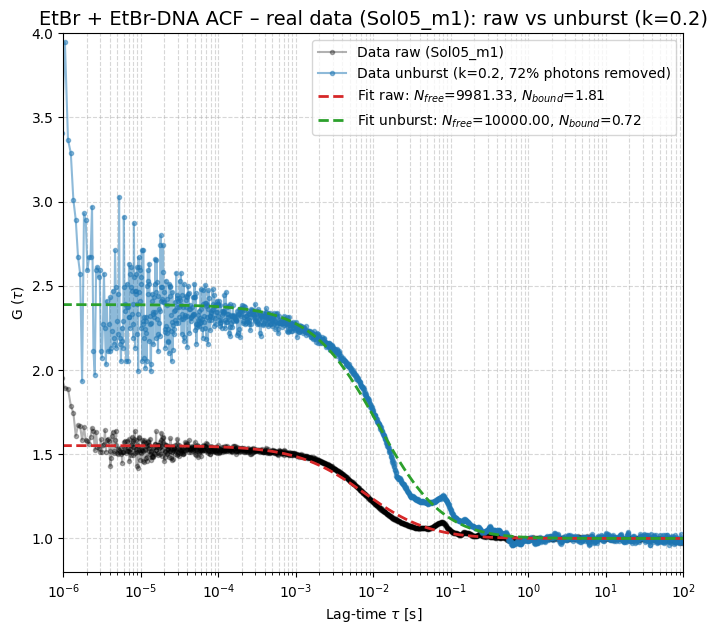

In [23]:
G_fit_dna_h = tk.diffusion_3d_double(tau_dna_h, *popt_dna_h)
G_fit_u_h = tk.diffusion_3d_double(tau_u_h, *popt_u_h)

fig = plt.figure(figsize=(8,7), dpi=100)
ax = fig.add_subplot(1,1,1)
ax.set_title("EtBr + EtBr-DNA ACF – real data (Sol05_m1): raw vs unburst (k=0.2)", fontsize=14)
ax.plot(
    tau_dna_h, G_dna_h, '.-', color='black', alpha=0.3,
    label='Data raw (Sol05_m1)',
)
ax.plot(
    tau_u_h, G_u_h, '.-', color='tab:blue', alpha=0.5,
    label=f'Data unburst (k=0.2, {100*(1 - len(ts_u_k02_h)/len(ts_dna_h)):.0f}% photons removed)',
)
ax.plot(
    tau_dna_h, G_fit_dna_h, '--', color='tab:red', lw=2,
    label=f'Fit raw: $N_{{free}}$={N_1_h:.2f}, $N_{{bound}}$={N_2_h:.2f}'
)
ax.plot(
    tau_u_h, G_fit_u_h, '--', color='tab:green', lw=2,
    label=f'Fit unburst: $N_{{free}}$={N_1_u_h:.2f}, $N_{{bound}}$={N_2_u_h:.2f}'
)
ax.set_xlabel("Lag-time $\\tau$ [s]")
ax.set_ylabel("G ($\\tau$)")
ax.set_xlim(1e-6, 1e2)
ax.set_ylim(0.8, 4.0)
ax.set_xscale('log')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.draw()
plt.savefig('./images/acf_etbr_dna_real_Sol05_m1_raw_vs_unburst_k0.2.png')

**Observations.** With Sol05_m1 the situation is even more severe than with Sol03_m1:

- **Raw fit:** the 2-species fit on the raw ACF is now fully degenerate: $N_{free} \approx 9981$ with an error of order $10^6$, i.e. the free species is no longer resolved at all (with Sol03_m1 the same fit still returned $N_{free} = 3.10 \pm 0.13$). The higher DNA concentration makes the burst contribution strong enough to dominate the ACF, exactly as in the simulation cases with many bound blobs.
- **Unburst $k = 0.2$:** removing every bin above $median + 0.2 \cdot MAD$ deletes ~72% of all photons — not bursts, since there is no burst population to isolate. The ACF amplitude collapses from $G(0) - 1 \approx 0.55$ (raw) to $\approx 1.4$ on a depleted trace with much lower statistics, and the fit returns $N_{free} \approx 10^4$ (pushed against the upper bound), worse than the raw fit.

**Take-away.** Increasing the DNA concentration makes things strictly worse: neither the raw fit nor any unburst preprocessing recovers $N_{free}$. This rules out the objection that the failure observed on real data was due to a sample with too little DNA: with Sol05_m1, where the bound fraction is larger, the workflow fails even more clearly.

### Conclusion

The unburst workflow, validated on noise-free simulations across 5 blob densities (with a clear $k \propto 1/N_{bound}$ scaling law), **does not transfer to real data** when the background is high and inseparable from the signal. This was verified on two samples with different bound fractions:

- **Sol03_m1 (lower DNA concentration):** the raw 2-species fit still recovers $N_{free} = 3.10 \pm 0.13$, but any unburst preprocessing — even the mildest threshold — destroys the result ($N_{free} = 7.87 \pm 2.16$ at $k = 0.2$). The unburst step is therefore **always harmful** on real data.
- **Sol05_m1 (higher DNA concentration):** even the raw fit degenerates ($N_{free} \to 10^4$), and unburst makes it worse still. A higher bound fraction does not help: it pushes the system further into the burst-dominated regime.

**Conditions for unburst applicability:**
1. Low background count rate (signal-to-background ratio $\gg 1$)
2. Bursts must be clearly distinguishable from the signal in the histogram (bimodal distribution with a gap)
3. The MAD must reflect the signal noise, not be inflated by background

**When these conditions are not met** (as in both real samples), the unburst method must not be used. The direct 2-species fit on raw data is the appropriate approach **as long as** the bound fraction is low enough that the ACF is not burst-dominated; beyond that limit, neither approach recovers $N_{free}$ and a different analysis strategy is required.

---

**Cross-reference.** The simulation notebook (`3a_simulation_analysis.ipynb`) demonstrates 
that the unburst workflow works correctly when the signal is clean. This notebook 
establishes the **boundary of applicability**: the method requires a clear 
signal-to-burst separation in the histogram, which is not satisfied under high-background 
conditions typical of real FCS measurements with EtBr.